In [ ]:
# Setup, run once (installs into the kernel's environment).
# Requires Python 3.10 or newer.
%pip install "qiskit>=2.5" "qiskit-nature>=0.8" qiskit-nature-pyscf pyscf qiskit-algorithms matplotlib scipy

# Variational Quantum Algorithms (VQA) with Qiskit

**Two VQA examples:**

1. **Part 1, Optimization:** MaxCut on a four node cycle with a hardware efficient ansatz
2. **Part 2, Chemistry:** H2 ground state with VQE (PySCF → qubit mapping → HEA → VQE)

> The VQA loop is always the same:
> **parameterized circuit** $U(\theta)$ --> **estimate** $\langle H \rangle$ with an Estimator --> **classical optimizer** proposes new $\theta$ --> repeat until convergence.

![VQA loop](images/vqe-loop.avif)

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

import qiskit
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.circuit.library import EfficientSU2
from qiskit.primitives import StatevectorEstimator

from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.second_q.mappers import JordanWignerMapper
from qiskit_nature.second_q.algorithms import GroundStateEigensolver
from qiskit_algorithms.minimum_eigensolvers import VQE, NumPyMinimumEigensolver
from qiskit_algorithms.optimizers import SLSQP

print("qiskit:", qiskit.__version__)
import qiskit_nature
import pyscf
print("qiskit-nature:", qiskit_nature.__version__, "| pyscf:", pyscf.__version__)

qiskit: 2.5.2
qiskit-nature: 0.8.0 | pyscf: 2.14.0


---
# Part 1: Quantum chemistry: H2 ground state with VQE

**Goal:** ground-state energy of H2 at equilibrium (0.735 Å) in the STO-3G basis.

Pipeline: **molecule (PySCF)** → first-quantized $H_{elec}$ → second quantization → **Jordan–Wigner to 4 qubits** → **hardware efficient (EfficientSU2) ansatz** → **VQE loop** → compare against exact (FCI).

## Step 1: Molecule to second-quantized Hamiltonian (PySCF driver)

Under Born–Oppenheimer the nuclei are frozen classical charges, so only electrons are quantum. The first-quantized electronic Hamiltonian (atomic units) has three parts plus a constant:

$$H = -\sum_i \frac{\nabla^2_i}{2} - \sum_{i,A} \frac{Z_A}{|r_i - R_A|} + \sum_{i<j} \frac{1}{|r_i - r_j|} + E_{nuc}$$

Electron kinetic energy, electron–nuclear attraction ($Z_A$ = nuclear charges at fixed positions $R_A$), electron–electron repulsion, plus the constant nuclear–nuclear repulsion $E_{nuc}$ (the 0.719969 Ha printed below). To put this on qubits we expand in the STO-3G atomic-orbital basis and go to second quantization, where electrons hop between spin-orbitals via fermionic operators:

$$H_{elec} = \sum_{pq} h_{pq} a^\dagger_p a_q + \tfrac12\sum_{pqrs} h_{pqrs} a^\dagger_p a^\dagger_q a_r a_s$$

$h_{pq}$ are the one-electron terms: kinetic energy and nuclear attraction. $h_{pqrs}$ are the two-electron terms: the interaction between electrons. PySCF computes both for this geometry (0.735 Å), so a new geometry means a new Hamiltonian.

In [ ]:
driver = PySCFDriver(atom="H 0 0 0; H 0 0 0.735", basis="sto3g")
problem = driver.run()
print("spatial orbitals:", problem.num_spatial_orbitals)
print("particles (alpha, beta):", problem.num_particles)
print(f"nuclear repulsion energy: {problem.nuclear_repulsion_energy:.6f} Ha")
print("second-quantized Hamiltonian terms:", len(problem.hamiltonian.second_q_op()))

spatial orbitals: 2
particles (alpha, beta): (1, 1)
nuclear repulsion energy: 0.719969 Ha
second-quantized Hamiltonian terms: 36


## Step 2: Fermions to qubits: Jordan–Wigner mapping

Each spin-orbital maps to one qubit (2 orbitals × 2 spins = **4 qubits**). Occupation becomes $|0\rangle$/$|1\rangle$.

In [ ]:
mapper = JordanWignerMapper()
qubit_op = mapper.map(problem.hamiltonian.second_q_op())
print(f"qubits: {qubit_op.num_qubits}, Pauli terms: {len(qubit_op)}")
print(qubit_op)

qubits: 4, Pauli terms: 15
SparsePauliOp(['IIII', 'IIIZ', 'IIZI', 'IIZZ', 'IZII', 'IZIZ', 'ZIII', 'ZIIZ', 'YYYY', 'XXYY', 'YYXX', 'XXXX', 'IZZI', 'ZIZI', 'ZZII'],
              coeffs=[-0.81054798+0.j,  0.17218393+0.j, -0.22575349+0.j,  0.12091263+0.j,
  0.17218393+0.j,  0.16892754+0.j, -0.22575349+0.j,  0.16614543+0.j,
  0.0452328 +0.j,  0.0452328 +0.j,  0.0452328 +0.j,  0.0452328 +0.j,
  0.16614543+0.j,  0.17464343+0.j,  0.12091263+0.j])


## Step 3: Ansatz (reps=2)

In [ ]:
hea_h2 = EfficientSU2(qubit_op.num_qubits, reps=2, entanglement="linear")
print(f"qubits: {hea_h2.num_qubits}, parameters: {hea_h2.num_parameters}")
print(hea_h2.decompose())

qubits: 4, parameters: 24
     ┌──────────┐┌──────────┐     ┌──────────┐┌───────────┐             »
q_0: ┤ Ry(θ[0]) ├┤ Rz(θ[4]) ├──■──┤ Ry(θ[8]) ├┤ Rz(θ[12]) ├─────────────»
     ├──────────┤├──────────┤┌─┴─┐└──────────┘└┬──────────┤┌───────────┐»
q_1: ┤ Ry(θ[1]) ├┤ Rz(θ[5]) ├┤ X ├─────■───────┤ Ry(θ[9]) ├┤ Rz(θ[13]) ├»
     ├──────────┤├──────────┤└───┘   ┌─┴─┐     └──────────┘├───────────┤»
q_2: ┤ Ry(θ[2]) ├┤ Rz(θ[6]) ├────────┤ X ├──────────■──────┤ Ry(θ[10]) ├»
     ├──────────┤├──────────┤        └───┘        ┌─┴─┐    ├───────────┤»
q_3: ┤ Ry(θ[3]) ├┤ Rz(θ[7]) ├─────────────────────┤ X ├────┤ Ry(θ[11]) ├»
     └──────────┘└──────────┘                     └───┘    └───────────┘»
«                  ┌───────────┐┌───────────┐                          
«q_0: ──────■──────┤ Ry(θ[16]) ├┤ Rz(θ[20]) ├──────────────────────────
«         ┌─┴─┐    └───────────┘├───────────┤┌───────────┐             
«q_1: ────┤ X ├──────────■──────┤ Ry(θ[17]) ├┤ Rz(θ[21]) ├─────────────
«     ┌───┴───┴───┐ 

## Step 4: VQE loop

In [ ]:
estimator = StatevectorEstimator()
vqe_history = []

def vqe_callback(eval_count, params, value, meta):
    vqe_history.append(float(value))

vqe = VQE(
    estimator,
    hea_h2,
    SLSQP(maxiter=200),
    initial_point=np.random.default_rng(7).uniform(-np.pi, np.pi, hea_h2.num_parameters),
    callback=vqe_callback,
)
solver = GroundStateEigensolver(mapper, vqe)
vqe_result = solver.solve(problem)
vqe_total = float(vqe_result.total_energies[0])
print(f"VQE total energy: {vqe_total:.6f} Ha  ({len(vqe_history)} evals)")

# Reference: exact diagonalization (FCI in this basis)

exact_result = GroundStateEigensolver(mapper, NumPyMinimumEigensolver()).solve(problem)
exact_total = float(exact_result.total_energies[0])

print(f"Exact (FCI) total: {exact_total:.6f} Ha")
print(f"VQE error vs exact: {(vqe_total - exact_total)*1000:.3f} mHa")

VQE total energy: -1.137305 Ha  (626 evals)
Exact (FCI) total: -1.137306 Ha
VQE error vs exact: 0.001 mHa


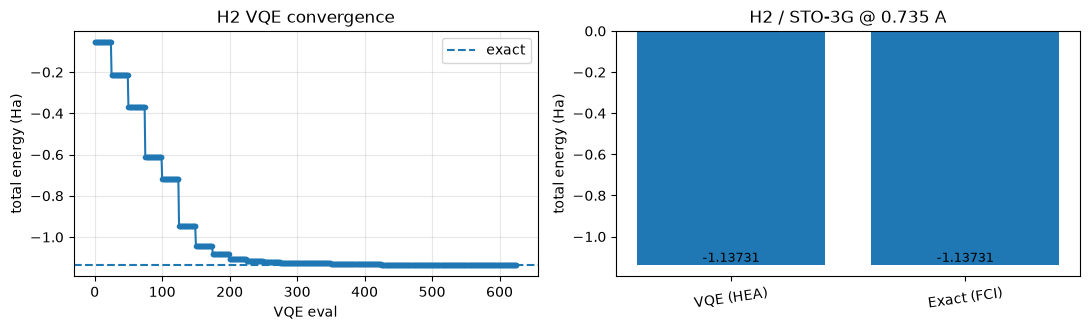

In [ ]:
# Convergence + energy comparison
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

axes[0].plot(np.array(vqe_history) + problem.nuclear_repulsion_energy, marker="o", ms=3)
axes[0].axhline(exact_total, ls="--", label="exact")
axes[0].set_xlabel("VQE eval"); axes[0].set_ylabel("total energy (Ha)")
axes[0].set_title("H2 VQE convergence")
axes[0].legend(); axes[0].grid(True, alpha=0.3)

labels = ["VQE (HEA)", "Exact (FCI)"]
vals = [vqe_total, exact_total]
axes[1].bar(labels, vals)
axes[1].set_ylabel("total energy (Ha)")
axes[1].set_title("H2 / STO-3G @ 0.735 A")
for i, v in enumerate(vals):
    axes[1].text(i, v, f"{v:.5f}", ha="center", va="bottom", fontsize=9)
plt.xticks(rotation=8)
plt.tight_layout()
plt.show()

---
# Part 2: Combinatorial optimization, MaxCut with a hardware efficient VQA

**MaxCut:** given a graph, color each node 0/1 to *maximize* the number of edges crossing the cut.

We use the **four node cycle** $0-1-2-3-0$ (4 edges). The optimum cut is **4** (alternate colors `0101` / `1010`).

<table style="border: none; margin: auto;">
  <tr style="border: none;">
    <td style="border: none; text-align: center;"><img src="images/four_node_cycle.png" width="300"><br>four node cycle</td>
    <td style="border: none; text-align: center; font-size: 2em;">→</td>
    <td style="border: none; text-align: center;"><img src="images/optimal_cut.png" width="300"><br>optimal cut</td>
  </tr>
  <tr style="border: none;">
    <td colspan="3" style="border: none; text-align: center;"><img src="images/suboptimal_cut.png" width="300"><br>suboptimal cut</td>
  </tr>
</table>

## Step 1: From the graph to the Hamiltonian (step by step)

Let $x_i \in \{0,1\}$ be the color of node $i$. Edge $(i,j)$ is cut iff $x_i \ne x_j$:

$$C(x) = \sum_{(i,j) \in E} (x_i + x_j - 2 x_i x_j) = \sum_{(i,j)} \frac{1 - z_i z_j}{2}, \quad z_i = 1-2x_i \in \{+1,-1\}$$

Why each term counts cut edges, truth table for a single edge $(i,j)$:

| $x_i$ | $x_j$ | cut? | $x_i + x_j - 2 x_i x_j$ | $(1 - z_i z_j)/2$ |
|---|---|---|---|---|
| 0 | 0 | no | 0 | 0 |
| 0 | 1 | **yes** | 1 | 1 |
| 1 | 0 | **yes** | 1 | 1 |
| 1 | 1 | no | 0 | 0 |

Substituting $z_i = 1 - 2x_i$: equal colors give $z_i z_j = +1$ (contributes 0); different colors give $z_i z_j = -1$ (contributes 1). Each term is exactly '1 if cut, else 0'.

Maximizing $C$ $\Leftrightarrow$ minimizing the Ising Hamiltonian. Let's expand $C$ to see why:

$$C(x) = \sum_{(i,j)} \frac{1}{2} - \frac{1}{2}\sum_{(i,j)} z_i z_j = \frac{|E|}{2} - \frac{1}{2}\sum_{(i,j)} z_i z_j$$

$|E|/2$ is a constant, so maximizing the cut is *exactly* minimizing:

$$H_{cost} = \sum_{(i,j) \in E} Z_i Z_j \qquad \left(C_{\max} = \frac{|E| - E_{\min}}{2}\right)$$

Each $Z_i Z_j$ becomes one Pauli term on 4 qubits (Qiskit little-endian: qubit 0 = rightmost character). Worked example on the 4-cycle: the coloring $x = (x_0,x_1,x_2,x_3) = (0,1,0,1)$, which is the Qiskit bitstring `1010` (written $q_3 q_2 q_1 q_0$), cuts all 4 edges, so $C = 4$. Equivalently $z = (+1,-1,+1,-1)$, every $z_i z_j = -1$, so $\langle H_{cost}\rangle = -4$. In general, $C_{\max} = \dfrac{|E| - E_{\min}}{2}$, where $E_{\min}$ is the minimum of $\langle H_{cost}\rangle$. The value $E_{\min} = -|E|$ (all edges cut) is reached only when the graph is bipartite, as the 4-cycle is.

In [ ]:
# 4-node cycle graph
n_qubits = 4
edges = [(0, 1), (1, 2), (2, 3), (3, 0)]
print("nodes:", list(range(n_qubits)))
print("edges:", edges)

# Build H_cost = sum ZZ step by step
terms = []
for i, j in edges:
    chars = ["I"] * n_qubits
    chars[i] = "Z"
    chars[j] = "Z"
    label = "".join(chars[::-1])  # little-endian
    terms.append((label, 1.0))
    print(f"edge ({i},{j}) -> {label}")

H_cost = SparsePauliOp.from_list(terms)
print("\nH_cost =")
print(H_cost)

nodes: [0, 1, 2, 3]
edges: [(0, 1), (1, 2), (2, 3), (3, 0)]
edge (0,1) -> IIZZ
edge (1,2) -> IZZI
edge (2,3) -> ZZII
edge (3,0) -> ZIIZ

H_cost =
SparsePauliOp(['IIZZ', 'IZZI', 'ZZII', 'ZIIZ'],
              coeffs=[1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j])


## Step 2: Trial state: the hardware efficient ansatz

Qiskit's `EfficientSU2`: each repetition is one rotation layer (Ry + Rz on every qubit, the $\theta$ parameters) plus one entanglement layer (CX chain 0-1-2-3).

In [ ]:
# Hardware-efficient trial state: layers of single-qubit rotations + linear CX chain.
# Treated as a black box — no ansatz theory needed for this demo.
hea = EfficientSU2(n_qubits, reps=1, entanglement="linear")
print(f"qubits: {hea.num_qubits}, parameters: {hea.num_parameters}")
print("pattern: parameterized rotations on every qubit, CX chain 0-1-2-3, repeated once")
print(hea.decompose())

qubits: 4, parameters: 16
pattern: parameterized rotations on every qubit, CX chain 0-1-2-3, repeated once
     ┌──────────┐┌──────────┐     ┌──────────┐┌───────────┐             »
q_0: ┤ Ry(θ[0]) ├┤ Rz(θ[4]) ├──■──┤ Ry(θ[8]) ├┤ Rz(θ[12]) ├─────────────»
     ├──────────┤├──────────┤┌─┴─┐└──────────┘└┬──────────┤┌───────────┐»
q_1: ┤ Ry(θ[1]) ├┤ Rz(θ[5]) ├┤ X ├─────■───────┤ Ry(θ[9]) ├┤ Rz(θ[13]) ├»
     ├──────────┤├──────────┤└───┘   ┌─┴─┐     └──────────┘├───────────┤»
q_2: ┤ Ry(θ[2]) ├┤ Rz(θ[6]) ├────────┤ X ├──────────■──────┤ Ry(θ[10]) ├»
     ├──────────┤├──────────┤        └───┘        ┌─┴─┐    ├───────────┤»
q_3: ┤ Ry(θ[3]) ├┤ Rz(θ[7]) ├─────────────────────┤ X ├────┤ Ry(θ[11]) ├»
     └──────────┘└──────────┘                     └───┘    └───────────┘»
«                  
«q_0: ─────────────
«                  
«q_1: ─────────────
«     ┌───────────┐
«q_2: ┤ Rz(θ[14]) ├
«     ├───────────┤
«q_3: ┤ Rz(θ[15]) ├
«     └───────────┘


## Step 3: The variational loop: Estimator + classical optimizer

Cost function: $f(\theta) = \langle \psi(\theta) | H_{cost} | \psi(\theta)\rangle$ via `StatevectorEstimator` (exact expectation; on hardware this would be shot averages). Minimize with `COBYLA`, a gradient-free optimizer that also tolerates shot noise.

In [ ]:
estimator = StatevectorEstimator()
history_hea = []

def cost_hea(theta):
    theta = np.asarray(theta)
    job = estimator.run([(hea, H_cost, [theta])])
    val = float(job.result()[0].data.evs[0])
    history_hea.append(val)
    return val

rng = np.random.default_rng(42)
x0 = rng.uniform(-np.pi, np.pi, hea.num_parameters)
res_hea = minimize(cost_hea, x0, method="COBYLA", options={"maxiter": 300})
print(f"initial <H> = {history_hea[0]:.4f}")
print(f"optimal <H> = {res_hea.fun:.4f}")
print(f"cut size = (|E| - <H>)/2 = {(len(edges) - res_hea.fun)/2:.3f}  (optimum = 4)")
print(f"optimizer evaluations: {res_hea.nfev}")

initial <H> = -1.4316
optimal <H> = -4.0000
cut size = (|E| - <H>)/2 = 4.000  (optimum = 4)
optimizer evaluations: 208


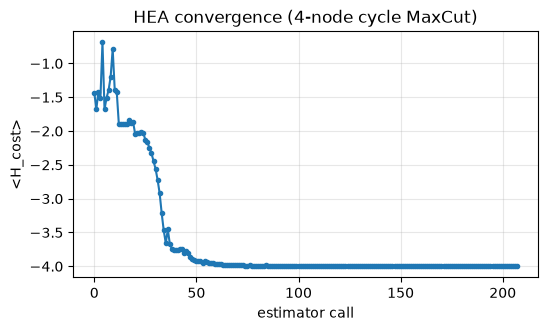

top assignments (bitstring = q3 q2 q1 q0) + cut value:
  1010  p=1.000  cut=4
  0010  p=0.000  cut=2
  1110  p=0.000  cut=2
  1011  p=0.000  cut=2
  0110  p=0.000  cut=2
  1101  p=0.000  cut=2


In [ ]:
# Convergence trace + most-likely assignment from the exact statevector
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(history_hea, marker="o", ms=3)
ax.set_xlabel("estimator call")
ax.set_ylabel("<H_cost>")
ax.set_title("HEA convergence (4-node cycle MaxCut)")
ax.grid(True, alpha=0.3)
plt.show()

sv = Statevector(hea.assign_parameters(res_hea.x))
probs = sv.probabilities_dict()
top = sorted(probs.items(), key=lambda kv: -kv[1])[:6]
print("top assignments (bitstring = q3 q2 q1 q0) + cut value:")
for bitstr, pr in top:
    z = np.array([1 if b == "0" else -1 for b in bitstr[::-1]])  # 0->+1, 1->-1
    # cut = sum (1 - zi*zj)/2
    cut = sum((1 - z[i]*z[j])/2 for i, j in edges)
    print(f"  {bitstr}  p={pr:.3f}  cut={int(cut)}")

### Result

The optimizer reaches $\langle H\rangle = -4$, i.e. cut **4** (verified against exact diagonalization below).

In [ ]:
# Exact check (no quantum needed): H_cost is diagonal, so its minimum is its smallest diagonal entry.
exact_min = float(np.min(np.real(np.diag(H_cost.to_matrix()))))
print(f"VQA   <H> = {res_hea.fun:.4f}  -> cut {(len(edges) - res_hea.fun)/2:.3f}")
print(f"exact min = {exact_min:.4f}  -> cut {(len(edges) - exact_min)/2:.3f}  (optimum = 4)")

VQA   <H> = -4.0000  -> cut 4.000
exact min = -4.0000  -> cut 4.000  (optimum = 4)
